## Energy consumption in Brussels

Sibelga regularly publishes the yearly consumption for the different municipalities in the Brussels region. Looking at the residential data, we can see that the average yearly consumption per household is around 2000 kWh, with some geographical differences: 

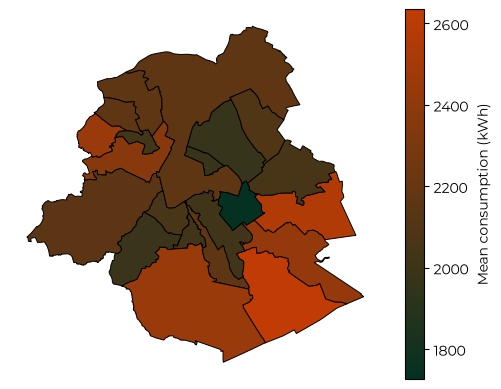

In [28]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

for f in Path("fonts").glob("*.ttf"):   # path relative to the notebook
    fm.fontManager.addfont(str(f))
plt.rcParams["font.family"] = "Montserrat"

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("swifft_map", ["#043122", "#C03C04"])

df_consumption = pd.read_csv("../data/202512-yearly-consumption-elec-2025.csv", sep=";", decimal=".")
df_consumption_res = df_consumption[df_consumption['CUSTOMER_TYPE_FR_TX'] == 'RES']
df_consumption_res['CITY_FR_TX'] = df_consumption_res['CITY_FR_TX'].replace(r"Brux.*", "Bruxelles", regex=True)
df_consumption_res['AVERAGE_KWH'] = df_consumption_res['VOLUME_KWH'] / df_consumption_res['COUNT_EAN']
df_mean_cons = df_consumption_res.groupby('CITY_FR_TX')['AVERAGE_KWH'].mean().sort_values(ascending=False)

# Load a polygon layer containing the Brussels municipalities.
municipalities = gpd.read_file("../data/limites-administratives-des-communes-en-region-de-bruxelles-capitale.geojson")
results = df_mean_cons.rename("mean_kwh").rename_axis("CITY_FR_TX").reset_index()
map_data = municipalities.merge(results, left_on="name_fr", right_on="CITY_FR_TX", how="left")

ax = map_data.plot(column="mean_kwh", cmap=cmap, legend=True, edgecolor="black", linewidth=0.7, missing_kwds={"color": "lightgrey", "label": "No data"}, legend_kwds={"label": "Mean consumption (kWh)"})
ax.set_axis_off()
fig = ax.get_figure()
plt.show()

The municipalities consuming a larger share of energy are the ones on the south: Woluwe-Saint-Pierre, Auderghem, Watermael-Boitsfort, Uccle, which also happen to be the richest municipalities. 
This is supported by looking at the average revenue data for the different municipaloties. The IBSA (Institut Bruxellois de Statistique et d'Analyse) publishes the equivalent mean revenue per inhabitant after taxes, and we can compare it with the mean consumption.

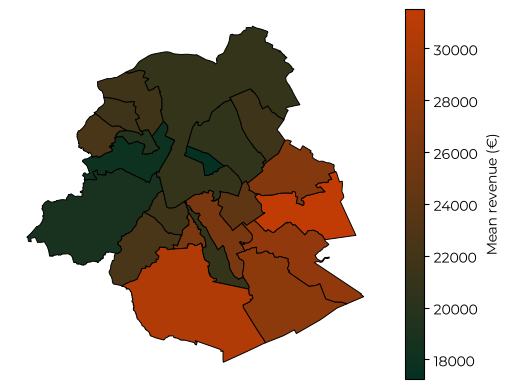

In [34]:
df_revenues = pd.read_excel("../data/2.1b_rev_dep_menages_stat_fisc_menages_prives_20260526.xlsx", sheet_name="2.1.5.7", skiprows=3, engine="calamine")
df_revenues = df_revenues.rename(columns={"Unnamed: 0": "CITY_FR_TX"})
df_revenues_2023 = df_revenues[["CITY_FR_TX", 2023]].rename(columns={2023: "AVG_REVENUE"})

df_joint = pd.merge(df_mean_cons, df_revenues_2023, on="CITY_FR_TX", how="left")
# print(df_joint)
map_data_revenues = municipalities.merge(df_joint, left_on="name_fr", right_on="CITY_FR_TX", how="left")
ax = map_data_revenues.plot(column="AVG_REVENUE", cmap=cmap, legend=True, edgecolor="black", linewidth=0.7, missing_kwds={"color": "lightgrey", "label": "No data"}, legend_kwds={"label": "Mean revenue (€)"})
ax.set_axis_off()
fig = ax.get_figure()
plt.show()



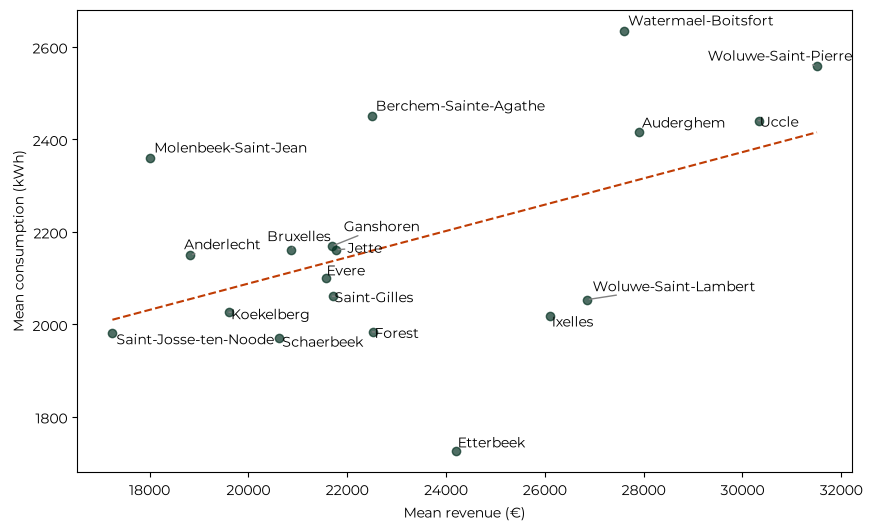

                            OLS Regression Results                            
Dep. Variable:            AVERAGE_KWH   R-squared:                       0.245
Model:                            OLS   Adj. R-squared:                  0.200
Method:                 Least Squares   F-statistic:                     5.502
Date:                Thu, 05 Nov 2026   Prob (F-statistic):             0.0314
Time:                        11:46:44   Log-Likelihood:                -127.52
No. Observations:                  19   AIC:                             259.0
Df Residuals:                      17   BIC:                             260.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        1519.2429    285.643      5.319      

In [52]:
import numpy as np
from adjustText import adjust_text
import statsmodels.api as sm

X = sm.add_constant(df_joint["AVG_REVENUE"])
model = sm.OLS(df_joint["AVERAGE_KWH"], X).fit()
intercept = model.params['const']
slope = model.params['AVG_REVENUE']

regression_line = np.zeros((2,))
regression_line[0] = intercept + slope * df_joint["AVG_REVENUE"].min()
regression_line[1] = intercept + slope * df_joint["AVG_REVENUE"].max()

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(df_joint["AVG_REVENUE"], df_joint["AVERAGE_KWH"], color='#043122', alpha=0.7)
ax.plot([df_joint["AVG_REVENUE"].min(), df_joint["AVG_REVENUE"].max()], regression_line, color="#C03C04", ls='--')
ax.set_xlabel("Mean revenue (€)")
ax.set_ylabel("Mean consumption (kWh)")

texts = [ax.text(xi, yi, l) for xi, yi, l in zip(df_joint["AVG_REVENUE"], df_joint["AVERAGE_KWH"], df_joint["CITY_FR_TX"])]
adjust_text(texts, arrowprops=dict(arrowstyle="-", color="gray"))

plt.show()

print(model.summary())


The data shows a clear correlation between revenue and energy consumption, with a confidence greater than 95%, even if the revenue explains only around 25% of the variance in the consumption, meaning that there are other factors that contributes to increase or decrease the energy consumption, of course. 
From one point of view, this is understandable considering that more purchasing power equates to bigger homes and thus higher consumption. However, from another point of view, a bigger revenue should allow for better houses which are more insulated, with more efficient energy systems. Evidently, the first mechanism is more powerful than the second one.
